# Residual Analysis: Single Energy Bin

This notebook demonstrates how to use `ResidualAnalysis` when the observed and expected histograms already contain one measured-energy (`Em`) bin. No energy selection is needed.

The workflow is:

1. Load matching observed and expected histograms.
2. Confirm that the input contains one `Em` bin.
3. Initialize `ResidualAnalysis` directly from those histograms.
4. Calculate a representative residual and generate its diagnostic plot.

Part II then documents every available projection, residual definition, statistic, simulation option, and plotting parameter.

## Navigation

| Section | Contents |
|---|---|
| [Part I: Complete practical workflow](#part-i) | Load the fitted DC4 products, initialize the classes, calculate residuals, and generate representative plots. |
| [Part II: API reference and advanced options](#part-ii) | Method documentation, parameters, restrictions, and customization. |
| [Using your own data](#using-your-own-data) | Replace the tutorial file and histogram objects safely. |
| [Available projections and residual types](#projections-and-residuals) | Inspect supported products and switch residual definitions. |
| [Plotting customization and Phi-bin selection](#plotting-customization) | Configure plotting options, running means, and HEALPix slices. |
| [Poisson Monte Carlo references](#poisson-monte-carlo) | Generate reproducible fixed-fit Pearson references. |
| [Statistical diagnostics](#statistical-diagnostics) | Produce the full-CDS descriptive statistics table. |

<a id="part-i"></a>

# PART I: Complete practical workflow

This part is a continuous, normal-use example. Run the cells in order to load the data, initialize both classes, calculate a representative residual, and generate a diagnostic plot. Detailed API explanations begin only in Part II.

## Setup

The following cells locate the `workflow` directory and import the histogram, residual-analysis, plotting, and display tools used in this notebook.

In [1]:
%load_ext autoreload
%autoreload 2

# Handle filesystem paths in a platform-independent way.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent
    if working_dir.name == "notebooks"
    else working_dir
)

# Make the local workflow modules importable.
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals

from histpy import Histogram
from IPython.display import display
import h5py
import numpy as np

## Load the residual products

`ResidualAnalysis` requires an observed-count histogram and the corresponding fitted expected-count histogram. The two histograms must have identical axes and shapes, and their counts must be finite and non-negative.

This notebook uses `workflow/data/residual/03_511_imaging_residual_products.hdf5`. Repository notebook `03_511_imaging_analysis.ipynb` writes this file from its final DC4 image-deconvolution result: `fitted_image` and `fitted_background_norm` are used to calculate the source, background, and total expectations before the histograms are exported. It is therefore a stored fitted DC4 product, and this tutorial does not rerun the fit.

To analyze another result, change `residual_file` and, if necessary, the `name` values used to load `observed` and `expected`. HDF5 object names can differ between files, so inspect them before calling `Histogram.open()`.

In [3]:
# Locate the single-energy-bin residual product.
residual_dir = repo_root / "data" / "residual"
residual_file = residual_dir / "03_511_imaging_residual_products.hdf5"

print("Input file:", residual_file)
print("File exists:", residual_file.exists())

Input file: /Users/maura/Documents/COSI/data-challenge-4/workflow/data/residual/03_511_imaging_residual_products.hdf5
File exists: True


In [4]:
# Inspect the available objects before choosing histogram names.
with h5py.File(residual_file, "r") as residual_data:
    available_objects = list(residual_data.keys())

print("Available objects:", available_objects)

Available objects: ['background_expectation', 'observed', 'source_expectation', 'total_expectation']


In [5]:
# Load the observed counts and total fitted expectation.
# Replace these names if the previous cell reports different objects.
observed = Histogram.open(
    residual_file,
    name="observed",
)

expected = Histogram.open(
    residual_file,
    name="total_expectation",
)

## Verify the input structure

Inspect both histograms before initializing the analysis. This example must report one `Em` bin. If a file reports multiple bins, use the multi-energy tutorial instead.

In [6]:
# Confirm that both histograms have matching dimensions.
energy_bin_count = observed.axes["Em"].nbins

print("Observed axes:", observed.axes.labels)
print("Expected axes:", expected.axes.labels)
print("Observed shape:", observed.shape)
print("Expected shape:", expected.shape)
print("Number of Em bins:", energy_bin_count)
print("Em bin edges:", observed.axes["Em"].edges)

if energy_bin_count != 1:
    raise ValueError(
        "This tutorial requires an input containing exactly one Em bin."
    )

Observed axes: ['Em' 'Phi' 'PsiChi']
Expected axes: ['Em' 'Phi' 'PsiChi']
Observed shape: (1, 60, 3072)
Expected shape: (1, 60, 3072)
Number of Em bins: 1
Em bin edges: [509. 513.] keV


## Initialize the analysis

Create the analysis directly from the matching histograms. This file already contains exactly one `Em` bin, so no energy-selection step is required. The stored expectation uses a known artificial floor of `1e-12`.

In [7]:
# No energy-selection step is needed for this input.
# This product uses a known artificial expected-count floor of 1e-12.
analysis = ResidualAnalysis(
    observed,
    expected,
    expected_floor=1e-12,
)

## Calculate a residual and generate a plot

At this point the data are loaded and `analysis` is initialized. A normal residual-analysis workflow now needs only three operations:

1. Calculate a residual histogram for a supported projection.
2. Initialize `PlottingResiduals` with the analysis object.
3. Request the same projection and residual definition from `plot()`.

The following cell uses raw residuals so the practical workflow has no simulation cost. It demonstrates the three principal visualization families: a 1D `Phi` diagnostic, paired rectangular `Phi-Chi` and `Phi-Psi` maps, and a Phi-integrated `PsiChi` HEALPix map. The direct residual variable is useful for numerical inspection or export; the plotter recalculates requested residuals internally and therefore does not receive that variable.

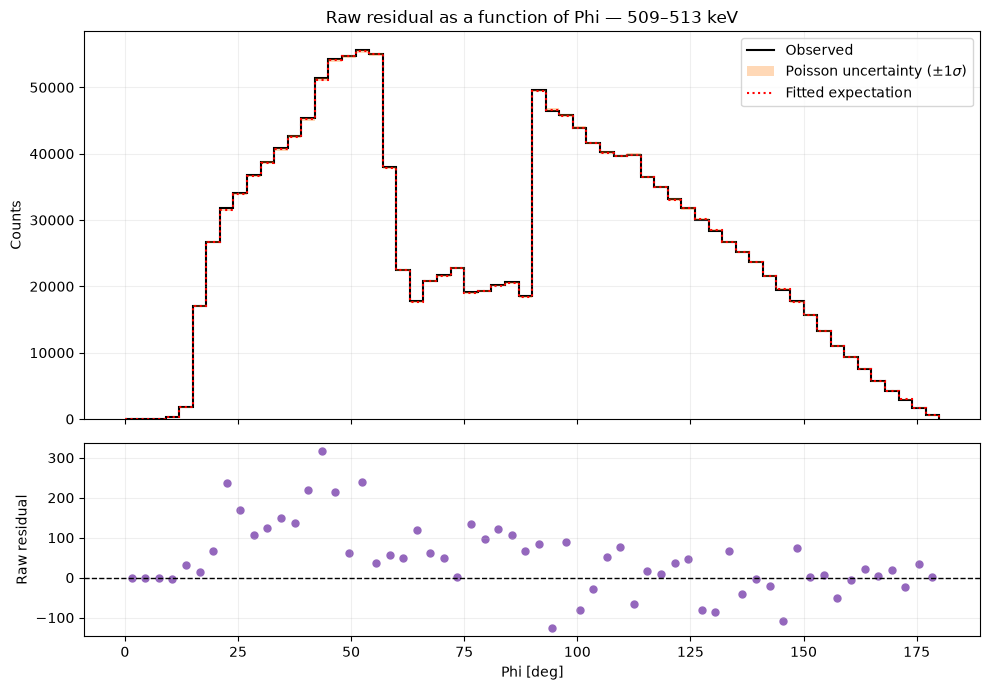

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1086: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


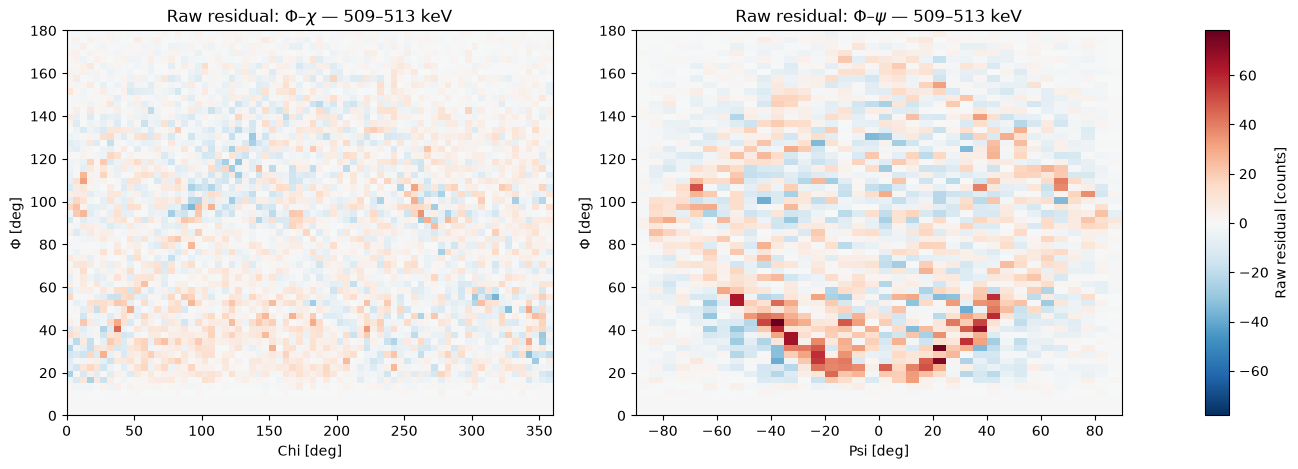

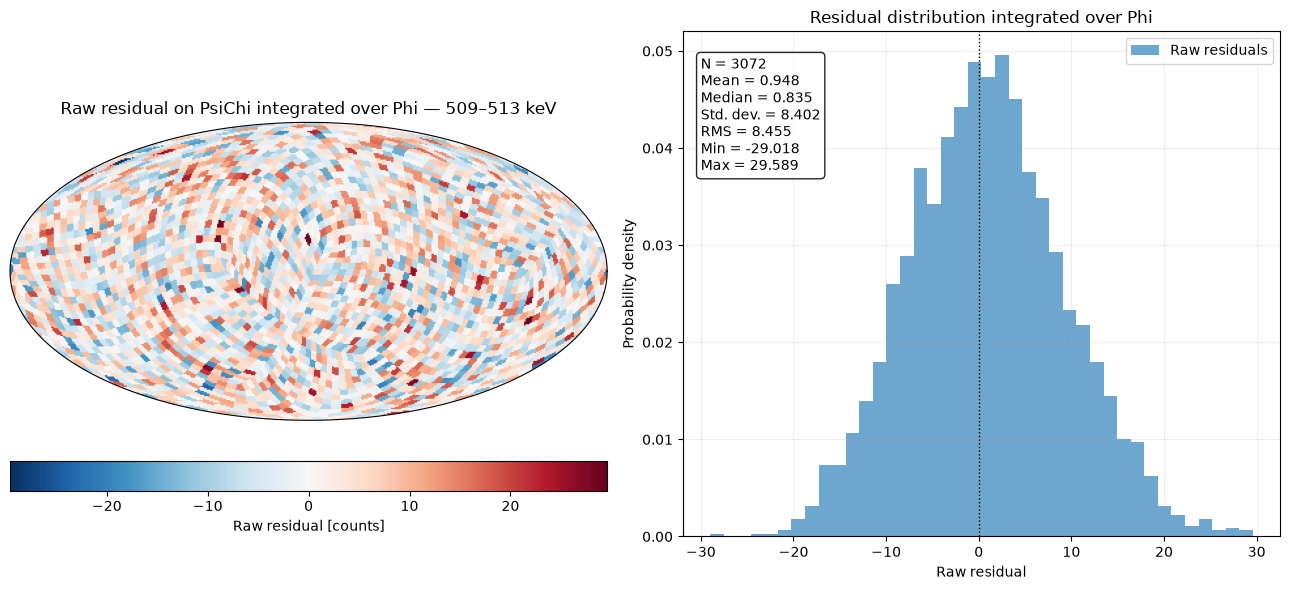

Residual axes: ['Phi']
Residual shape: (60,)


In [8]:
# Calculate one residual histogram for direct numerical use.
standard_phi_residual = analysis.residual_function(
    "Phi_projection",
    residual_type="raw",
)

# Give the completed analysis object to the plotting interface.
standard_plotter = PlottingResiduals(analysis)

# Generate a representative one-dimensional diagnostic.
standard_phi_figure = standard_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# One rectangular request displays both Phi-Chi and Phi-Psi maps.
standard_angular_2d_figure = standard_plotter.plot(
    "Phi_Chi_projection",
    residual_type="raw",
)

# Display the PsiChi residual map integrated over Phi.
standard_psichi_figure = standard_plotter.plot(
    "PsiChi_projection",
    residual_type="raw",
)

print("Residual axes:", standard_phi_residual.axes.labels)
print("Residual shape:", standard_phi_residual.shape)

### What the workflow produced

`standard_phi_residual` is a one-dimensional HistPy histogram containing observed-minus-expected counts in each `Phi` bin. Its plot reveals broad trends versus Compton-scatter angle. The paired rectangular maps show where residual structure depends jointly on `Phi` and either `Chi` or `Psi`. The HEALPix view preserves the full `PsiChi` geometry and reveals localized angular structure after integrating over `Phi`. Together these plots provide complementary views of the same masked observed and expected counts.

<a id="part-ii"></a>

# PART II: API reference, customization, and advanced diagnostics

The remaining sections document the complete interface and explain how to change masking, projections, residual definitions, Poisson references, statistical summaries, and plotting parameters. They are not additional prerequisites for the Part I workflow.

### Method reference

| Class | Method | Role in this tutorial |
|---|---|---|
| `ResidualAnalysis` | `__init__()` | Validate matching inputs and create masked copies. |
| | `mask_function()` | Define valid CDS bins and report exclusions. |
| | `projection_function()` | Retain requested axes and integrate all others. |
| | `split_psichi_function()` | Convert a `PsiChi` HEALPix axis into separate `Chi` and `Psi` histograms. |
| | `projected_data()` | Build and cache every supported one-bin projection. |
| | `residual_function()` | Calculate raw, Pearson, or fractional residuals after projection. |
| | `statistics_table()` | Summarize residuals in valid full-CDS bins. |
| | `pearson_poisson_reference()` | Simulate the Pearson reference for one view. |
| | `prepare_pearson_poisson_references()` | Simulate several views from shared full-CDS realizations. |
| `PlottingResiduals` | `__init__()` | Store an analysis and optional simulation/slice defaults. |
| | `plot()` | Route a projection to its 1D, rectangular, or HEALPix diagnostic. |

<a id="using-your-own-data"></a>

## Using your own data

Replace the tutorial path and HDF5 object names with those from your analysis. Both objects must be HistPy `Histogram` instances containing finite, non-negative counts, with identical axes and shapes. `observed` holds measured counts and `expected` holds the fitted total expectation used for the residual calculation.

```python
# Replace these three values with your own file and object names.
residual_file = repo_root / "data" / "residual" / "your_products.hdf5"
observed_name = "observed"
expected_name = "total_expectation"

observed = Histogram.open(residual_file, name=observed_name)
expected = Histogram.open(residual_file, name=expected_name)

# Use a numeric value only if the producing workflow inserted a known floor.
expected_floor = None
analysis = ResidualAnalysis(observed, expected, expected_floor=expected_floor)

print("Em edges:", observed.axes["Em"].edges)
```

Leave `expected_floor=None` for ordinary fitted expectations. Supply a value only when the data-producing workflow deliberately replaced zero or invalid expectations with a known artificial floor; use that exact value. The mask excludes floor-level bins only when they contain no observed events. Inspect the printed `Em` edges and bin count to decide whether this single-bin workflow applies; use Notebook 09 when multiple energy bins must be preserved or selected.

### Analysis construction

**Method: `ResidualAnalysis.__init__()`**

- **Purpose:** Validate matching observed and expected histograms, build the valid-bin mask, and store masked copies.
- **Parameters:** `observed` and `expected` are `Histogram` objects with identical axes and shape; `expected_floor=None` is an optional known artificial floor.
- **Returns:** A `ResidualAnalysis` object. Initialization itself returns `None`.
- **Example:** Part I creates `analysis` from the loaded products.
- **Customization:** Provide `expected_floor` only when the producing workflow deliberately inserted a known artificial expected-count floor; otherwise leave it as `None`. It is not a general low-count cut.
- **Notes:** With a one-bin input, initialize directly and do not call `select_energy_range()`. Floor-level bins are masked only when they contain zero observed counts; observed events at the floor raise `ValueError`.

### Inspect the mask

**Method: `mask_function()`**

- **Purpose:** Mark bins with usable expectation and summarize which bins were excluded.
- **Parameters:** None; it uses the histograms and `expected_floor` stored by the constructor.
- **Returns:** `(valid_mask, mask_report)`, where the mask is a Boolean array with the original CDS shape and the report is a dictionary.
- **Example:** The constructor already called this method; the next cell verifies the stored result.
- **Customization:** Set `expected_floor` at construction time, not here.
- **Notes:** A floor bin is excluded only if its observed count is zero. The method raises an error instead of hiding observed events. Every later projection starts from the masked copies.

In [9]:
# Recalculate the mask only to demonstrate the public method.
valid_mask, mask_report = analysis.mask_function()
print("Stored and recalculated masks agree:", np.array_equal(valid_mask, analysis.mask))
display(mask_report)

Stored and recalculated masks agree: True


{'total_bins': 184320,
 'valid_bins': np.int64(175104),
 'excluded_bins': np.int64(9216),
 'observed_counts_excluded': np.float64(0.0),
 'expected_floor': 1e-12,
 'minimum_expected': <Quantity 1.e-12>,
 'minimum_retained_expected': <Quantity 0.00156623>}

### Build a projection directly

**Method: `projection_function()`**

- **Purpose:** Project the masked observed and expected counts onto the named axes. Axes not named are integrated out.
- **Parameters:** `*axis_names`: one or more axis labels, such as `"Phi"` or `"Phi", "PsiChi"`.
- **Returns:** A dictionary with matching `observed` and `expected` histograms.
- **Example:** The next cell retains only `Phi`.
- **Customization:** Pass any labels shown in `observed.axes.labels`.
- **Notes:** The same projection is applied to both products, and the method always starts from masked histograms.

In [10]:
# Retain Phi and integrate over Em and PsiChi.
phi_products = analysis.projection_function("Phi")
print("Projected axes:", phi_products["observed"].axes.labels)
print("Observed and expected shapes:", phi_products["observed"].shape, phi_products["expected"].shape)

Projected axes: ['Phi']
Observed and expected shapes: (60,) (60,)


### Split the HEALPix coordinate

**Method: `split_psichi_function()`**

- **Purpose:** Rebin a `PsiChi` HEALPix projection into separate longitude-like `Chi` and latitude-like `Psi` coordinates.
- **Parameters:** `psichi_products` is a dictionary of histograms sharing `PsiChi`; `bin_width=5.0` is the output angular width in degrees.
- **Returns:** Dictionaries named from the retained axes, here `Chi` and `Psi`, each containing observed and expected histograms.
- **Example:** The next cell starts from a direct `PsiChi` projection.
- **Customization:** Change `bin_width` when a different rectangular angular sampling is needed.
- **Notes:** Counts are checked for preservation. Most users can rely on `projected_data()`, which calls this method automatically.

In [11]:
# Project to PsiChi, then form separate Chi and Psi products.
psichi_products = analysis.projection_function("PsiChi")
split_products = analysis.split_psichi_function(psichi_products)
print("Split products:", tuple(split_products))
print("Chi axes:", split_products["Chi"]["observed"].axes.labels)
print("Psi axes:", split_products["Psi"]["observed"].axes.labels)

Split products: ('Chi', 'Psi')
Chi axes: ['Chi']
Psi axes: ['Psi']


<a id="projections-and-residuals"></a>

## Inspect all supported projections

**Method: `projected_data()`**

- **Purpose:** Build and cache the complete projection set appropriate for the number of `Em` bins.
- **Parameters:** None.
- **Returns:** A dictionary keyed by projection ID; every entry contains `observed` and `expected`.
- **Example:** The next cell lists every available ID, axis set, and shape.
- **Customization:** Use a returned ID in `residual_function()` or `PlottingResiduals.plot()`.
- **Notes:** Repeated calls reuse the cached products.

`projected_data()` applies identical operations to the masked observed and expected histograms. With one `Em` bin, it returns the energy projection and the standard CDS projections. Each dictionary entry contains an `observed` histogram and an `expected` histogram.

This step is useful when the projected counts must be inspected, tested, manipulated, or exported. It is not required before plotting because `PlottingResiduals` calls `projected_data()` internally.

In [12]:
# Generate and inspect every projection available for this analysis.
projected_products = analysis.projected_data()

for projection_name, products in projected_products.items():
    print(
        projection_name,
        "| axes:",
        products["observed"].axes.labels,
        "| shape:",
        products["observed"].shape,
    )

Phi_projection | axes: ['Phi'] | shape: (60,)
Chi_projection | axes: ['Chi'] | shape: (72,)
Psi_projection | axes: ['Psi'] | shape: (36,)
PsiChi_projection | axes: ['PsiChi'] | shape: (3072,)
Phi_Chi_projection | axes: ['Phi' 'Chi'] | shape: (60, 72)
Phi_Psi_projection | axes: ['Phi' 'Psi'] | shape: (60, 36)
Phi_PsiChi_projection | axes: ['Phi' 'PsiChi'] | shape: (60, 3072)
Em_projection | axes: ['Em'] | shape: (1,)


## Access a residual histogram directly

**Method: `residual_function()`**

- **Purpose:** Calculate residuals from one pair of already matched projected histograms.
- **Parameters:** `projection_id` is a key returned by `projected_data()`; `residual_type="raw"` also accepts `"pearson"` or `"fractional"`.
- **Returns:** A `Histogram` with the projection axes and residual values.
- **Example:** The next cell calculates Pearson residuals versus `Phi`.
- **Customization:** Change either argument to retrieve a different supported result.
- **Notes:** Pearson and fractional residuals are `NaN` where projected expectation is not positive. Plotting calls this method internally, so the variable below is needed only for direct numerical work or export.

`residual_function(projection_id, residual_type)` calculates residuals after projection. Every available projection supports three definitions:

- `"raw"`: observed minus expected counts.
- `"pearson"`: observed minus expected, divided by the square root of expected.
- `"fractional"`: observed minus expected, divided by expected.

The following cell uses `Phi_projection` as one representative example. This direct call is useful when residual values are needed for calculations or export. It is not required before plotting because `PlottingResiduals` calls `residual_function()` internally.

In [13]:
# Modify these two variables to retrieve another supported residual.
projection_id = "Phi_projection"
residual_type = "pearson"

phi_residual = analysis.residual_function(
    projection_id,
    residual_type,
)

print("Residual axes:", phi_residual.axes.labels)
print("Residual shape:", phi_residual.shape)
print("Finite residuals:", np.isfinite(phi_residual.contents).sum())

Residual axes: ['Phi']
Residual shape: (60,)
Finite residuals: 57


<a id="poisson-monte-carlo"></a>

## Build fixed-fit Poisson references

**Method: `pearson_poisson_reference()`**

- **Purpose:** Produce the simulated Pearson-residual density and pointwise 95% interval for one projection.
- **Parameters:** `projection_id`; `n_simulations=1000`; distribution `bins=15`; `seed=None`; and `phi_bin_index=None` or `energy_bin_index=None`, which becomes required only for its matching sliced HEALPix projection.
- **Returns:** A dictionary containing `bin_edges`, mean `density`, `lower`, `upper`, and the effective `seed`.
- **Example:** The next cell requests the `Phi` reference.
- **Customization:** Increase `n_simulations` for the final analysis; use a fixed seed for reproducibility.
- **Notes:** `n_simulations` must be an integer of at least 2 and `bins` a positive integer. This is a fixed-fit diagnostic, not a fitted goodness-of-fit test. Results are cached.

**Method: `prepare_pearson_poisson_references()`**

- **Purpose:** Prepare multiple projection references from the same full-CDS Poisson realizations.
- **Parameters:** `projection_bins` maps IDs to distribution-bin counts; `n_simulations=1000`; `seed=None`; `phi_bin_indices=None`; and `energy_bin_indices=None`.
- **Returns:** A dictionary keyed by `(projection_id, slice_index)`. Unsliced projections use `None`.
- **Example:** The second call below prepares a rectangular view and one `Phi_PsiChi` slice together.
- **Customization:** Use about 15 distribution bins for 1D views and 40 for maps.
- **Notes:** Prefer this method when several plots need references because each full-CDS realization is generated once and reused. Slice-index mappings are accepted only for their corresponding `Phi_PsiChi_projection` or `Em_PsiChi_projection`.

In [14]:
# Use a small simulation count for a quick tutorial run.
phi_reference = analysis.pearson_poisson_reference(
    "Phi_projection", n_simulations=50, bins=15, seed=42
)

shared_references = analysis.prepare_pearson_poisson_references(
    {"Phi_Chi_projection": 40, "Phi_PsiChi_projection": 40},
    n_simulations=50,
    seed=42,
    phi_bin_indices={"Phi_PsiChi_projection": 30},
)
print("Single-reference fields:", tuple(phi_reference))
print("Shared-reference keys:", tuple(shared_references))

Single-reference fields: ('bin_edges', 'density', 'lower', 'upper', 'seed')
Shared-reference keys: (('Phi_Chi_projection', None), ('Phi_PsiChi_projection', 30))


<a id="plotting-customization"></a>

## Plot residual diagnostics

**Method: `PlottingResiduals.__init__()`**

- **Purpose:** Store one analysis object and reusable defaults for Pearson simulations and HEALPix slices.
- **Parameters:** `analysis`; `n_simulations=None`; `random_seed=None`; `phi_bin_index=None`; and `energy_bin_index=None`.
- **Returns:** A `PlottingResiduals` object. Initialization itself returns `None`.
- **Example:** The next cell creates `plotter`.
- **Customization:** Constructor values are defaults and can be overridden by `plot()`.
- **Notes:** `energy_bin_index` is used only by multi-energy `Em_PsiChi_projection`.

**Method: `plot()`**

- **Purpose:** Select the correct 1D, paired rectangular, energy-coordinate, or HEALPix plotting layout.
- **Parameters:** `projection_id`; `residual_type="raw"`; `phi_bin_index=None`; `running_mean_window=None`; `n_simulations=None`; `random_seed=None`; `show_gaussian_reference=None`; and `energy_bin_index=None`. Plot-level simulation values fall back to constructor defaults.
- **Returns:** The Matplotlib `Figure`. The method also displays it.
- **Example:** The next cells show one 1D plot, the paired rectangular plot, and a sliced HEALPix plot.
- **Customization:** `running_mean_window` is available only for 1D Pearson plots. Poisson simulations and the Gaussian reference apply only to Pearson residuals.
- **Notes:** The plotter obtains projections and residuals from `analysis`; direct variables such as `phi_residual` are illustrative and are not plot inputs.

`PlottingResiduals` needs only the `ResidualAnalysis` object. The optional projected and residual variables created above are not passed to the plotter. `n_simulations` enables fixed-fit Poisson reference distributions for Pearson residuals, and `random_seed` makes those simulations reproducible. Increase `n_simulations` for a smoother final reference.

The first example shows a one-dimensional projection. Change only `projection_id` to use `Chi_projection` or `Psi_projection`. It also demonstrates `running_mean_window=5`, which draws a centered Pearson-residual average and is valid only for 1D Pearson plots. `show_gaussian_reference=True` explicitly overlays the standard-normal density; with its default `None`, the Gaussian appears when Monte Carlo is off and is hidden when Monte Carlo is enabled. For `raw` or `fractional` residuals, change `residual_type` and omit all Pearson-only options.

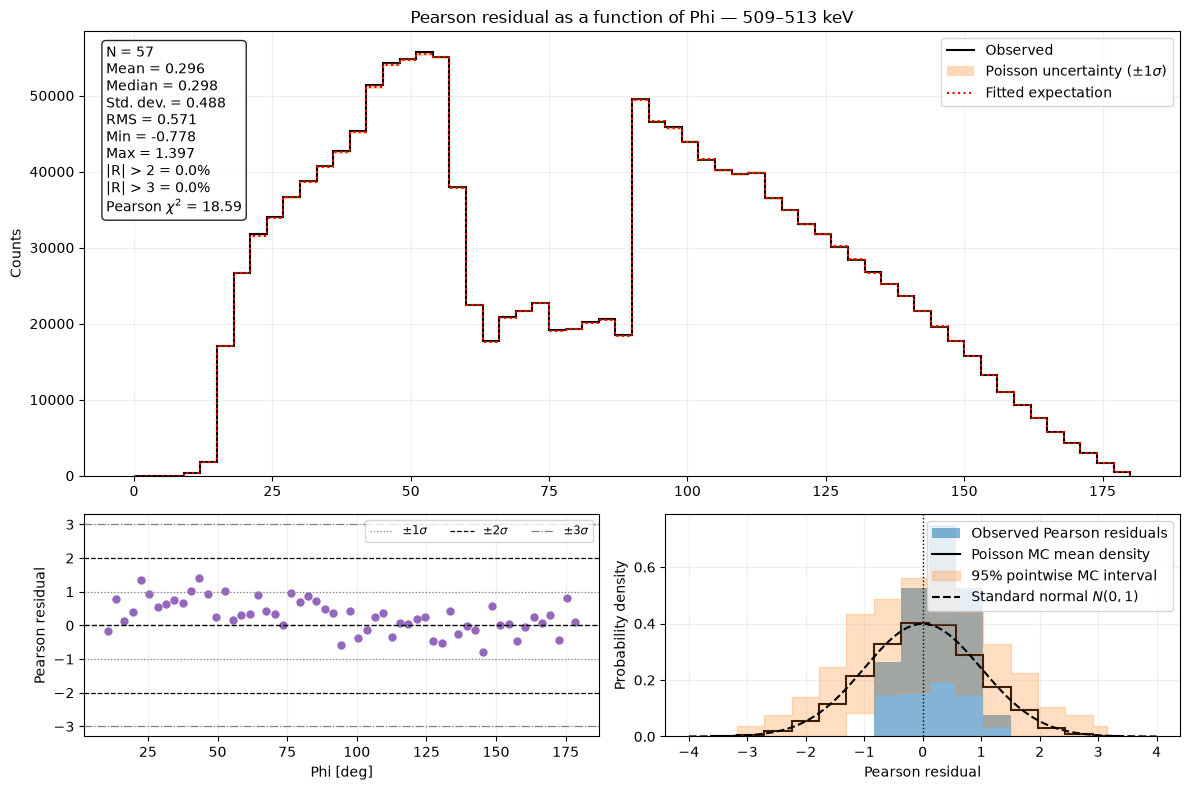

In [15]:
# Modify these values to control Monte Carlo cost and reproducibility.
n_simulations = 50
random_seed = 42

# Configure the plotter once and reuse it for this analysis object.
plotter = PlottingResiduals(
    analysis,
    n_simulations=n_simulations,
    random_seed=random_seed,
)

# Plot one representative one-dimensional CDS projection.
phi_figure = plotter.plot(
    "Phi_projection",
    residual_type="pearson",
    show_gaussian_reference=True,
)

### Paired rectangular projections

Requesting either `Phi_Chi_projection` or `Phi_Psi_projection` produces one figure containing both maps, with a shared color scale. The single call below is therefore sufficient to demonstrate both two-dimensional combinations.

/Users/maura/Documents/COSI/data-challenge-4/workflow/src/plot_residuals.py:1086: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()


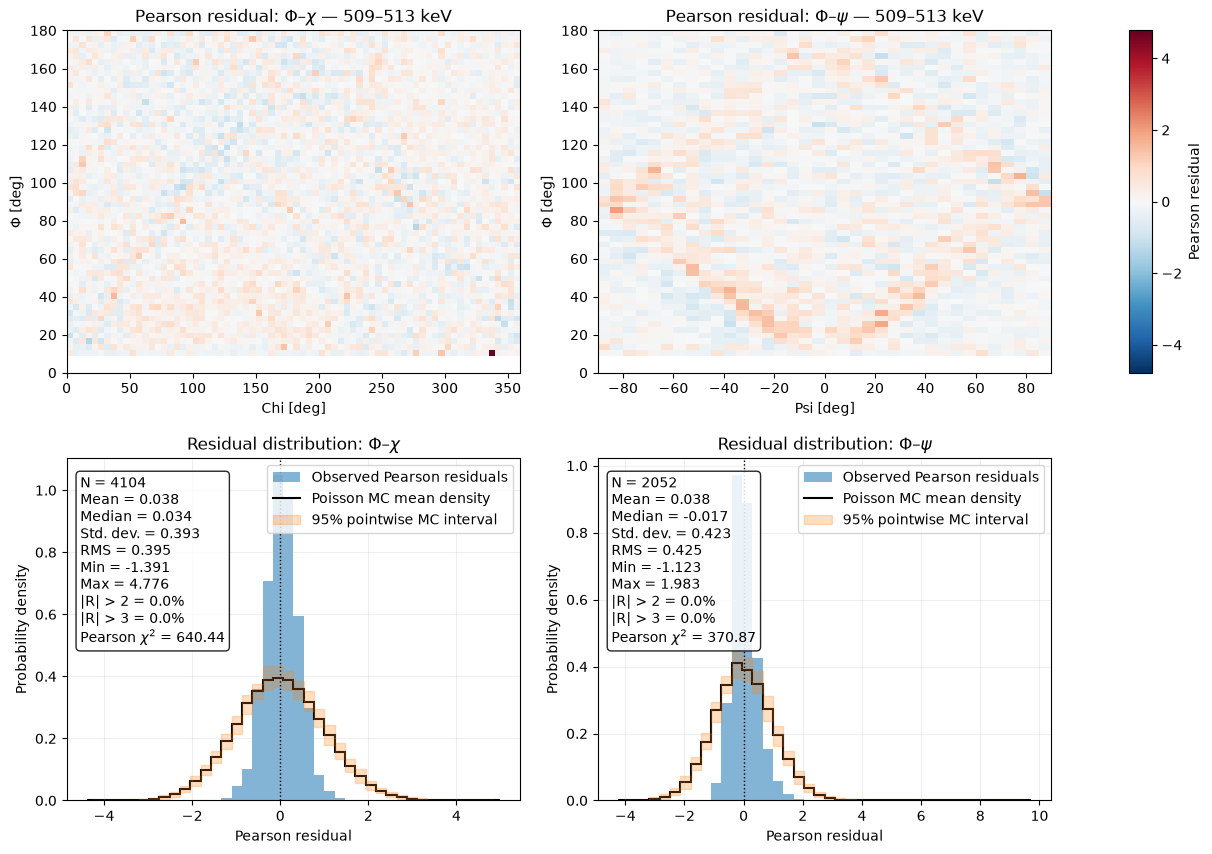

In [16]:
# One call displays the paired Phi-Chi and Phi-Psi diagnostics.
angular_2d_figure = plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)

### HEALPix projections

`PsiChi_projection` displays one HEALPix map integrated over `Phi`. `Phi_PsiChi_projection` retains `Phi`, so plotting it requires a zero-based `phi_bin_index` to choose which `Phi` slice to display. Valid indices run from `0` through `observed.axes["Phi"].nbins - 1`. The index changes only the displayed map; it does not alter the analysis object.

For Pearson residuals, the selected slice must contain positive expected counts after masking. The example chooses the middle valid `Phi` bin from the actual axis. Modify only `phi_bin_index` after inspecting the printed valid range and selected edges.

Valid phi_bin_index range: 0 to 59
Displayed Phi interval: 90.0 deg to 93.0 deg


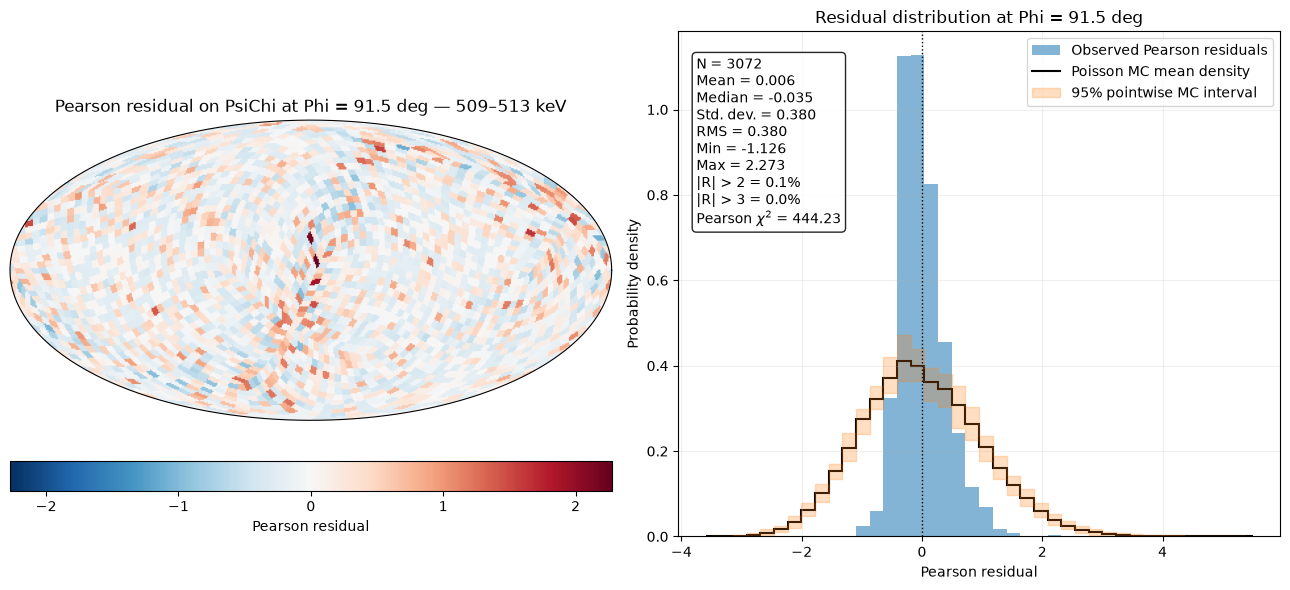

In [17]:
# Inspect the valid zero-based range, then choose the slice to display.
phi_axis = observed.axes["Phi"]
phi_edges = phi_axis.edges
print("Valid phi_bin_index range: 0 to", phi_axis.nbins - 1)

# Modify this variable to display another valid Phi slice.
phi_bin_index = phi_axis.nbins // 2

print(
    "Displayed Phi interval:",
    phi_edges[phi_bin_index],
    "to",
    phi_edges[phi_bin_index + 1],
)

phi_psichi_figure = plotter.plot(
    "Phi_PsiChi_projection",
    residual_type="pearson",
    phi_bin_index=phi_bin_index,
    show_gaussian_reference=False,
)

<a id="statistical-diagnostics"></a>

## Display the statistics table

**Method: `statistics_table()`**

- **Purpose:** Summarize one residual definition across valid full-CDS bins.
- **Parameters:** `residual_type`: `"raw"`, `"pearson"`, or `"fractional"`.
- **Returns:** A one-row pandas `DataFrame`. Pearson adds threshold fractions, Pearson chi-square, and Poisson deviance.
- **Example:** The next cell displays the Pearson table.
- **Customization:** Change only the residual type for the other tables.
- **Notes:** This is a full-CDS summary, not a summary of the last plot. It does not calculate fitted degrees of freedom or a goodness-of-fit probability.

In [18]:
# Use "raw" or "fractional" for the other residual definitions.
display(analysis.statistics_table("pearson"))

,Valid bins (N),Mean residual,Median residual,Std. dev.,Residual RMS,Minimum residual,Maximum residual,|R| > 2 [%],|R| > 3 [%],Pearson chi-square,Poisson deviance
0,175104,0.006482,-0.095382,0.456881,0.456927,-1.626413,17.35212,0.401476,0.223867,36558.590854,25525.814956


## Plotting helper responsibilities

These private methods are implementation details; use `plot()` instead of calling them directly.

| Private helper | Responsibility |
|---|---|
| `_prepare_pearson_references()` | Requests and caches all applicable Poisson references for one plotting configuration. |
| `_plot_1d_projection()` | Draws observed and expected steps, residual points, optional running mean, and normalized-residual distribution. |
| `_plot_2d_projections()` | Draws the paired `Phi-Chi` and `Phi-Psi` maps and their distributions. |
| `_plot_psichi_projection()` | Draws an integrated or sliced HEALPix map and its residual distribution. |
| `_format_residual_statistics()` | Formats the descriptive annotation shown on normalized-residual plots. |

## Projection reference

| Projection ID | Retained axes | Histogram dimensionality | Energy mode | Visualization produced by `plot()` |
|---|---|---:|---|---|
| `Em_projection` | `Em` | 1D | One original bin or one aggregated range | 1D counts and residual diagnostic |
| `Phi_projection` | `Phi` | 1D | Energy-integrated single-bin analysis | 1D counts and residual diagnostic |
| `Chi_projection` | `Chi` | 1D | Energy-integrated single-bin analysis | 1D counts and residual diagnostic |
| `Psi_projection` | `Psi` | 1D | Energy-integrated single-bin analysis | 1D counts and residual diagnostic |
| `PsiChi_projection` | `PsiChi` | 1D HEALPix axis | Energy-integrated single-bin analysis | Phi-integrated HEALPix map and distribution |
| `Phi_Chi_projection` | `Phi`, `Chi` | 2D | Energy-integrated single-bin analysis | Paired rectangular `Phi-Chi` and `Phi-Psi` maps |
| `Phi_Psi_projection` | `Phi`, `Psi` | 2D | Energy-integrated single-bin analysis | Same paired rectangular figure |
| `Phi_PsiChi_projection` | `Phi`, `PsiChi` | 2D (`Phi` plus HEALPix) | Energy-integrated single-bin analysis | HEALPix map for one `phi_bin_index` |

### Configurable plotting options

| Option | Default | Applies to |
|---|---|---|
| `residual_type` | `"raw"` | Every projection; also accepts `"pearson"` and `"fractional"` |
| `phi_bin_index` | `None` | Required for `Phi_PsiChi_projection`; zero-based |
| `energy_bin_index` | `None` | Used only by the multi-energy notebook |
| `running_mean_window` | `None` | Positive integer for 1D Pearson plots only |
| `n_simulations` | Constructor value or `None` | Fixed-fit Poisson reference for Pearson plots only |
| `random_seed` | Constructor value or `None` | Reproducible Poisson simulations |
| `show_gaussian_reference` | Automatic | Pearson plots only; shown by default without Monte Carlo and hidden with Monte Carlo |

Passing `n_simulations` or `show_gaussian_reference` with raw or fractional residuals raises `ValueError`. A running mean is rejected for non-Pearson or non-1D plots.